In [1]:
import os
import json
import cv2
import matplotlib.pyplot as plt

# 1. Cek isi direktori input Kaggle untuk memastikan nama folder persisnya
for dirname, _, filenames in os.walk('/kaggle/input'):
    print(dirname)
    if len(filenames) > 0:
        print("  Contoh file:", filenames[:3])


/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/solesensei
/kaggle/input/datasets/solesensei/solesensei_bdd100k
/kaggle/input/datasets/solesensei/solesensei_bdd100k/bdd100k
/kaggle/input/datasets/solesensei/solesensei_bdd100k/bdd100k/bdd100k
/kaggle/input/datasets/solesensei/solesensei_bdd100k/bdd100k/bdd100k/images
/kaggle/input/datasets/solesensei/solesensei_bdd100k/bdd100k/bdd100k/images/100k
/kaggle/input/datasets/solesensei/solesensei_bdd100k/bdd100k/bdd100k/images/100k/test
  Contoh file: ['cb2fe290-8786cd14.jpg', 'cb8b28d3-ab96a5fc.jpg', 'cbed3fd1-314723c8.jpg']
/kaggle/input/datasets/solesensei/solesensei_bdd100k/bdd100k/bdd100k/images/100k/test/testA
  Contoh file: ['cb1f05ca-28b96d3e.jpg', 'cb2382b5-9cc2c304.jpg', 'cb25355a-3ac85fc1.jpg']
/kaggle/input/datasets/solesensei/solesensei_bdd100k/bdd100k/bdd100k/images/100k/test/testB
  Contoh file: ['cb2512c2-c2d1b0f2.jpg', 'cb253f3b-b54796d8.jpg', 'cb25d527-e041ee3a.jpg']
/kaggle/input/datasets/solesensei/solesensei_b

In [ ]:
import os
import json
import cv2
import matplotlib.pyplot as plt

# 1. Cari lokasi pasti file JSON label train
base_dir = '/kaggle/input/datasets/solesensei/solesensei_bdd100k'
json_path = None

for root, dirs, files in os.walk(base_dir):
    for f in files:
        if 'labels_images_train.json' in f:
            json_path = os.path.join(root, f)
            break

print("File label ditemukan di:", json_path)

# 2. Baca isi file JSON (ini butuh waktu sekitar 5-10 detik karena filenya besar)
with open(json_path, 'r') as f:
    labels_data = json.load(f)

print(f"Total data train berlabel: {len(labels_data)} gambar")
print("\nContoh struktur 1 data (gambar pertama):")
print(json.dumps(labels_data[0], indent=2)[:800]) # Menampilkan 800 karakter pertama


In [ ]:
import shutil
import random
from tqdm import tqdm

# 1. Mapping 10 kelas utama BDD100K ke angka (0-9) untuk YOLO
CLASSES = [
    "car", "bus", "truck", "train", "motor",
    "bike", "person", "rider", "traffic light", "traffic sign"
]
class_to_id = {cls: i for i, cls in enumerate(CLASSES)}

# 2. Cari path file gambar berdasarkan nama file (karena gambar tersebar di folder trainA/trainB/val)
img_root = '/kaggle/input/datasets/solesensei/solesensei_bdd100k/bdd100k/bdd100k/images/100k'
print("Mengindeks lokasi semua gambar (butuh ~10 detik)...")
img_path_map = {}
for root, _, files in os.walk(img_root):
    for f in files:
        if f.endswith('.jpg'):
            img_path_map[f] = os.path.join(root, f)

print(f"Total file .jpg terindeks: {len(img_path_map)}")

# 3. Visualisasi sampel pertama untuk verifikasi (penting untuk dokumentasi GitHub!)
sample = labels_data[0]
sample_img_path = img_path_map[sample['name']]
img = cv2.imread(sample_img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

for obj in sample.get('labels', []):
    if 'box2d' in obj and obj['category'] in class_to_id:
        box = obj['box2d']
        x1, y1, x2, y2 = int(box['x1']), int(box['y1']), int(box['x2']), int(box['y2'])
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(img, obj['category'], (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 0), 2)

plt.figure(figsize=(12, 7))
plt.imshow(img)
plt.title(f"Ground Truth: {sample['name']} | Cuaca: {sample['attributes']['weather']}")
plt.axis('off')
plt.show()


In [ ]:
import os
import json
import shutil
import random
from tqdm import tqdm

# 1. Buat struktur folder standar YOLO di direktori kerja Kaggle (/kaggle/working)
yolo_base = '/kaggle/working/bdd_yolo'
for split in ['train', 'val']:
    os.makedirs(f'{yolo_base}/images/{split}', exist_ok=True)
    os.makedirs(f'{yolo_base}/labels/{split}', exist_ok=True)

# 2. Load file JSON validation juga
val_json_path = json_path.replace('train.json', 'val.json')
with open(val_json_path, 'r') as f:
    val_labels_data = json.load(f)

# Fungsi konversi koordinat BDD (x1, y1, x2, y2) -> YOLO (x_center, y_center, width, height ternormalisasi)
def convert_to_yolo(data_list, split_name, max_samples):
    random.seed(42) # Agar hasil sampling konsisten (reproducible)
    sampled_data = random.sample(data_list, min(max_samples, len(data_list)))
    
    IMG_W, IMG_H = 1280.0, 720.0 # Resolusi standar gambar BDD100K
    converted_count = 0
    
    for item in tqdm(sampled_data, desc=f"Memproses {split_name}"):
        img_name = item['name']
        if img_name not in img_path_map:
            continue
            
        yolo_lines = []
        for obj in item.get('labels', []):
            if 'box2d' in obj and obj['category'] in class_to_id:
                cls_id = class_to_id[obj['category']]
                box = obj['box2d']
                
                # Hitung titik tengah dan lebar/tinggi ternormalisasi (0 - 1)
                x_center = ((box['x1'] + box['x2']) / 2.0) / IMG_W
                y_center = ((box['y1'] + box['y2']) / 2.0) / IMG_H
                width = (box['x2'] - box['x1']) / IMG_W
                height = (box['y2'] - box['y1']) / IMG_H
                
                # Pastikan nilai valid di antara 0 dan 1
                if width > 0 and height > 0:
                    yolo_lines.append(f"{cls_id} {x_center:.6f} {y_center:.6f} {width:.6f} {height:.6f}")
        
        # Hanya simpan gambar yang memiliki minimal 1 objek berlabel
        if len(yolo_lines) > 0:
            # Copy gambar ke folder YOLO
            shutil.copy(img_path_map[img_name], f"{yolo_base}/images/{split_name}/{img_name}")
            # Tulis file label .txt
            txt_name = img_name.replace('.jpg', '.txt')
            with open(f"{yolo_base}/labels/{split_name}/{txt_name}", 'w') as out_f:
                out_f.write('\n'.join(yolo_lines))
            converted_count += 1
            
    print(f"Selesai {split_name}: {converted_count} gambar & label siap.")

# Jalankan konversi untuk 2.500 train dan 500 val
convert_to_yolo(labels_data, 'train', 2500)
convert_to_yolo(val_labels_data, 'val', 500)

# 3. Buat file konfigurasi dataset (data.yaml) yang wajib ada untuk YOLO
yaml_content = f"""path: {yolo_base}
train: images/train
val: images/val

nc: {len(CLASSES)}
names: {CLASSES}
"""

with open('/kaggle/working/bdd100k.yaml', 'w') as f:
    f.write(yaml_content)

print("\nFile konfigurasi bdd100k.yaml berhasil dibuat!")


In [ ]:
# Instal library ultralytics (YOLOv8)
!pip install -q ultralytics

from ultralytics import YOLO

# Gunakan model YOLOv8s (Small) - keseimbangan terbaik antara kecepatan dan akurasi
model = YOLO('yolov8s.pt')

# Mulai proses training!
results = model.train(
    data='/kaggle/working/bdd100k.yaml',
    epochs=15,          # 15 putaran belajar (cukup untuk melihat hasil tajam dalam ~12 menit)
    imgsz=640,          # Ukuran gambar standar untuk YOLO
    batch=16,           # Jumlah gambar yang diproses bersamaan di GPU
    project='/kaggle/working/runs',
    name='bdd100k_yolov8s',
    device=0            # Gunakan GPU
)


In [ ]:
import glob
import random
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# 1. Load model terbaik dari folder bdd100k_yolov8s-2
run_dir = '/kaggle/working/runs/bdd100k_yolov8s-2'
best_model = YOLO(f'{run_dir}/weights/best.pt')

# 2. Gabungkan Grafik Training Curves & Confusion Matrix untuk dokumentasi GitHub
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

results_img = cv2.cvtColor(cv2.imread(f'{run_dir}/results.png'), cv2.COLOR_BGR2RGB)
cm_img = cv2.cvtColor(cv2.imread(f'{run_dir}/confusion_matrix_normalized.png'), cv2.COLOR_BGR2RGB)

axes[0].imshow(results_img)
axes[0].set_title("Training & Validation Metrics Curves", fontsize=14, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(cm_img)
axes[1].set_title("Normalized Confusion Matrix", fontsize=14, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.savefig('/kaggle/working/portfolio_evaluation.png', dpi=150)
plt.show()

# 3. Uji Coba (Inference) pada 4 gambar baru dari folder TEST
test_images = glob.glob('/kaggle/input/datasets/solesensei/solesensei_bdd100k/bdd100k/bdd100k/images/100k/test/*.jpg')
random.seed(101)
sample_tests = random.sample(test_images, 4)

predictions = best_model.predict(sample_tests, conf=0.35, save=False)

fig, axes = plt.subplots(2, 2, figsize=(18, 11))
axes = axes.flatten()

for i, pred in enumerate(predictions):
    annotated_img = cv2.cvtColor(pred.plot(), cv2.COLOR_BGR2RGB)
    axes[i].imshow(annotated_img)
    axes[i].set_title(f"Hasil Deteksi AI - Test Sample #{i+1}", fontsize=12, fontweight='bold')
    axes[i].axis('off')

plt.tight_layout()
plt.savefig('/kaggle/working/portfolio_predictions.png', dpi=150)
plt.show()

print("Selesai! Kedua gambar portofolio siap diunduh.")


In [3]:
import os
import glob
import cv2
from ultralytics import YOLO

# 1. Ambil path string pertama dari hasil pencarian file .pt
pt_files = glob.glob('/kaggle/input/**/*.pt', recursive=True)
print("File model ditemukan:", pt_files)
model_save_path = pt_files[0]

# 2. Inisialisasi model & buka video
model = YOLO(model_save_path)
video_input = "/kaggle/input/datasets/wannnsion95/video1/dataset1.mp4"
video_output = "/kaggle/working/adas_demo_output.mp4"

cap = cv2.VideoCapture(video_input)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = int(cap.get(cv2.CAP_PROP_FPS)) or 30
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

print(f"Resolusi: {width}x{height} | FPS: {fps} | Total Frame: {total_frames}")

fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter(video_output, fourcc, fps, (width, height))

# 3. Variabel ByteTrack Counter & Collision Warning
counting_line_y = int(height * 0.65)
counted_ids = set()
class_counts = {"car": 0, "truck": 0, "bus": 0, "motor": 0, "person": 0}
track_history = {}

max_frames = min(total_frames, 300)
frame_idx = 0

while cap.isOpened() and frame_idx < max_frames:
    ret, frame = cap.read()
    if not ret:
        break
    frame_idx += 1

    results = model.track(frame, persist=True, tracker="bytetrack.yaml", conf=0.35, verbose=False)
    collision_warning = False

    # Garis sensor penghitung kendaraan
    cv2.line(frame, (0, counting_line_y), (width, counting_line_y), (0, 255, 255), 2)
    cv2.putText(frame, "COUNTING LINE", (15, counting_line_y - 10),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 255), 2)

    if results[0].boxes is not None and results[0].boxes.id is not None:
        boxes = results[0].boxes.xyxy.cpu().numpy()
        track_ids = results[0].boxes.id.int().cpu().numpy()
        cls_ids = results[0].boxes.cls.int().cpu().numpy()
        confs = results[0].boxes.conf.cpu().numpy()

        for box, track_id, cls_id, conf in zip(boxes, track_ids, cls_ids, confs):
            x1, y1, x2, y2 = map(int, box)
            cls_name = model.names[cls_id]
            cx, cy = (x1 + x2) // 2, (y1 + y2) // 2

            # Forward Collision Warning (jalur tengah & jarak dekat)
            box_height_ratio = (y2 - y1) / height
            in_ego_lane = (width * 0.30) < cx < (width * 0.70)
            is_close = box_height_ratio > 0.32 and cls_name in ["car", "truck", "bus"]

            if in_ego_lane and is_close:
                collision_warning = True
                box_color = (0, 0, 255)
                label = f"ID:{track_id} {cls_name} [TOO CLOSE]"
            else:
                box_color = (0, 255, 0)
                label = f"ID:{track_id} {cls_name} {conf:.2f}"

            cv2.rectangle(frame, (x1, y1), (x2, y2), box_color, 2)
            cv2.circle(frame, (cx, cy), 4, (255, 0, 255), -1)
            cv2.putText(frame, label, (x1, y1 - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.55, box_color, 2)

            # Virtual Line Crossing Counter
            prev_y = track_history.get(track_id, cy)
            if track_id not in counted_ids:
                if (prev_y < counting_line_y <= cy) or (prev_y > counting_line_y >= cy):
                    counted_ids.add(track_id)
                    if cls_name in class_counts:
                        class_counts[cls_name] += 1
            track_history[track_id] = cy

    # HUD Dashboard
    cv2.rectangle(frame, (10, 10), (300, 175), (0, 0, 0), -1)
    cv2.putText(frame, "ADAS TRAFFIC ANALYTICS", (20, 35), cv2.FONT_HERSHEY_SIMPLEX, 0.62, (255, 255, 255), 2)
    y_offset = 65
    for k, v in class_counts.items():
        cv2.putText(frame, f"{k.upper()}: {v}", (20, y_offset), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 255, 200), 2)
        y_offset += 22

    if collision_warning:
        cv2.rectangle(frame, (width // 2 - 220, 20), (width // 2 + 220, 75), (0, 0, 255), -1)
        cv2.putText(frame, "WARNING: COLLISION RISK!", (width // 2 - 195, 55),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.85, (255, 255, 255), 3)

    out.write(frame)

cap.release()
out.release()
print(f"\nSelesai memproses {frame_idx} frame!")
print("Total Kendaraan Melintas:", class_counts)

File model ditemukan: ['/kaggle/input/models/wannnsion95/bdd-weights/pytorch/default/1/best.pt']
Resolusi: 848x480 | FPS: 59 | Total Frame: 1833
requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 328ms
Prepared 1 package in 79ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 0.9s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


Selesai memproses 300 frame!
Total Kendaraan Melintas: {'car': 0, 'truck': 0, 'bus': 0, 'motor': 3, 'person': 2}


GIF animasi berhasil dibuat: /kaggle/working/adas_demo.gif (75 frames)


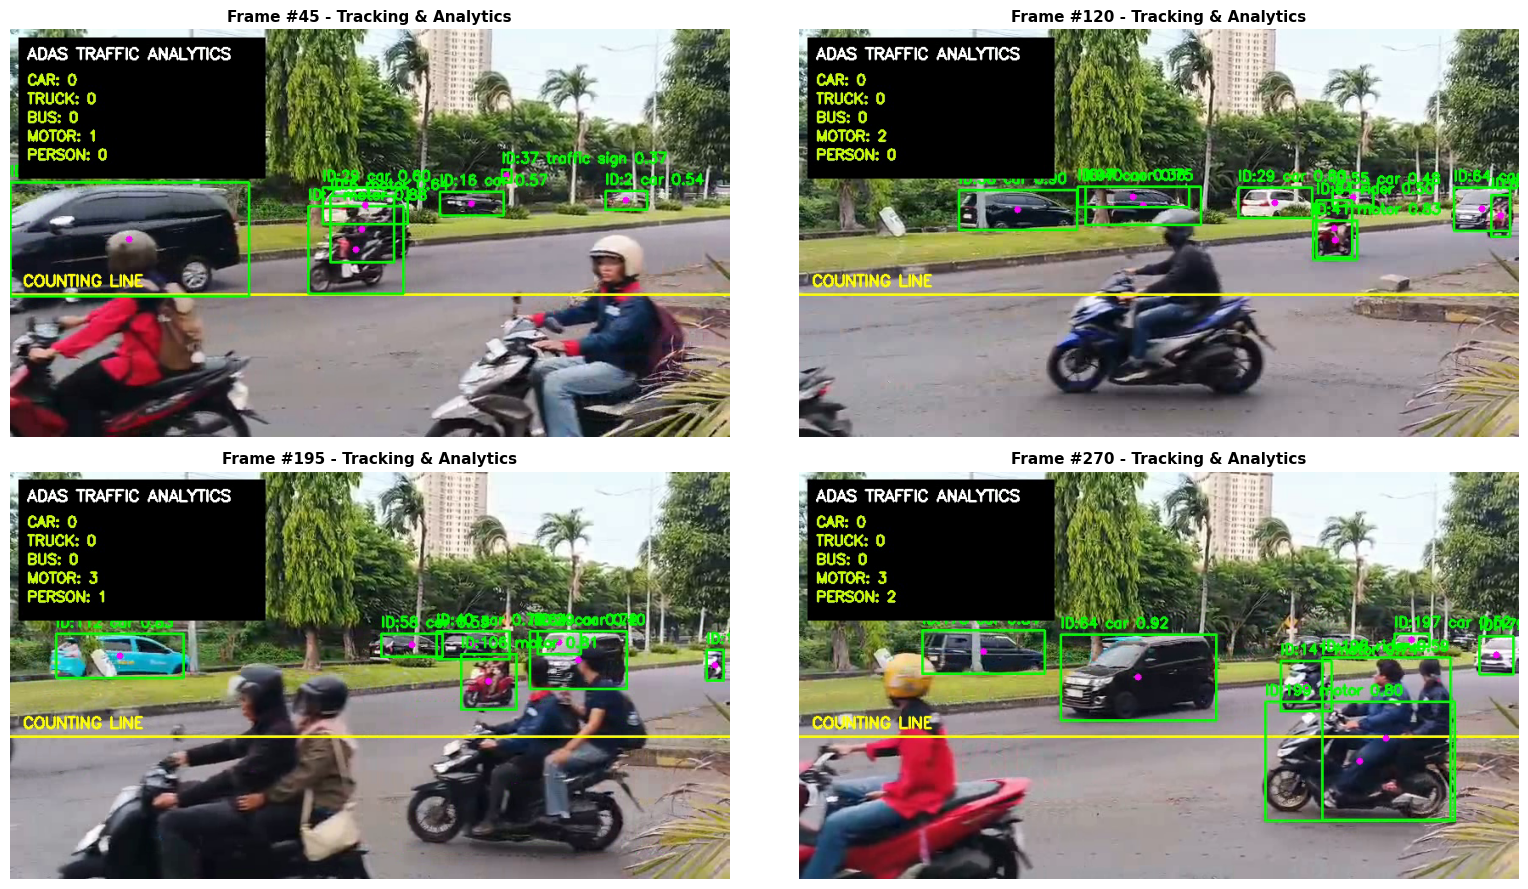

In [5]:
import cv2
import matplotlib.pyplot as plt
from PIL import Image

video_output = "/kaggle/working/adas_demo_output.mp4"
cap = cv2.VideoCapture(video_output)

total_out_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
sample_indices = [int(total_out_frames * r) for r in [0.15, 0.40, 0.65, 0.90]]

preview_frames = []
gif_frames = []

idx = 0
while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break
    
    rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    
    # Simpan 4 frame kunci untuk inspeksi visual
    if idx in sample_indices and len(preview_frames) < 4:
        preview_frames.append((idx, rgb_frame))
    
    # Ambil setiap frame ke-4 untuk membuat GIF animasi yang ringan & halus (~15 FPS)
    if idx % 4 == 0:
        pil_img = Image.fromarray(rgb_frame).resize((640, 362))
        gif_frames.append(pil_img)
        
    idx += 1

cap.release()

# 1. Simpan GIF animasi dari elemen pertama list (gif_frames[0])
gif_path = "/kaggle/working/adas_demo.gif"
gif_frames[0].save(
    gif_path,
    save_all=True,
    append_images=gif_frames[1:],
    duration=65,
    loop=0,
    optimize=True
)
print(f"GIF animasi berhasil dibuat: {gif_path} ({len(gif_frames)} frames)")

# 2. Tampilkan 4 cuplikan frame di layar Kaggle untuk inspeksi
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
axes = axes.flatten()

for i, (f_idx, img) in enumerate(preview_frames):
    axes[i].imshow(img)
    axes[i].set_title(f"Frame #{f_idx} - Tracking & Analytics", fontsize=11, fontweight='bold')
    axes[i].axis('off')

plt.tight_layout()
plt.savefig("/kaggle/working/adas_video_frames.png", dpi=150)
plt.show()


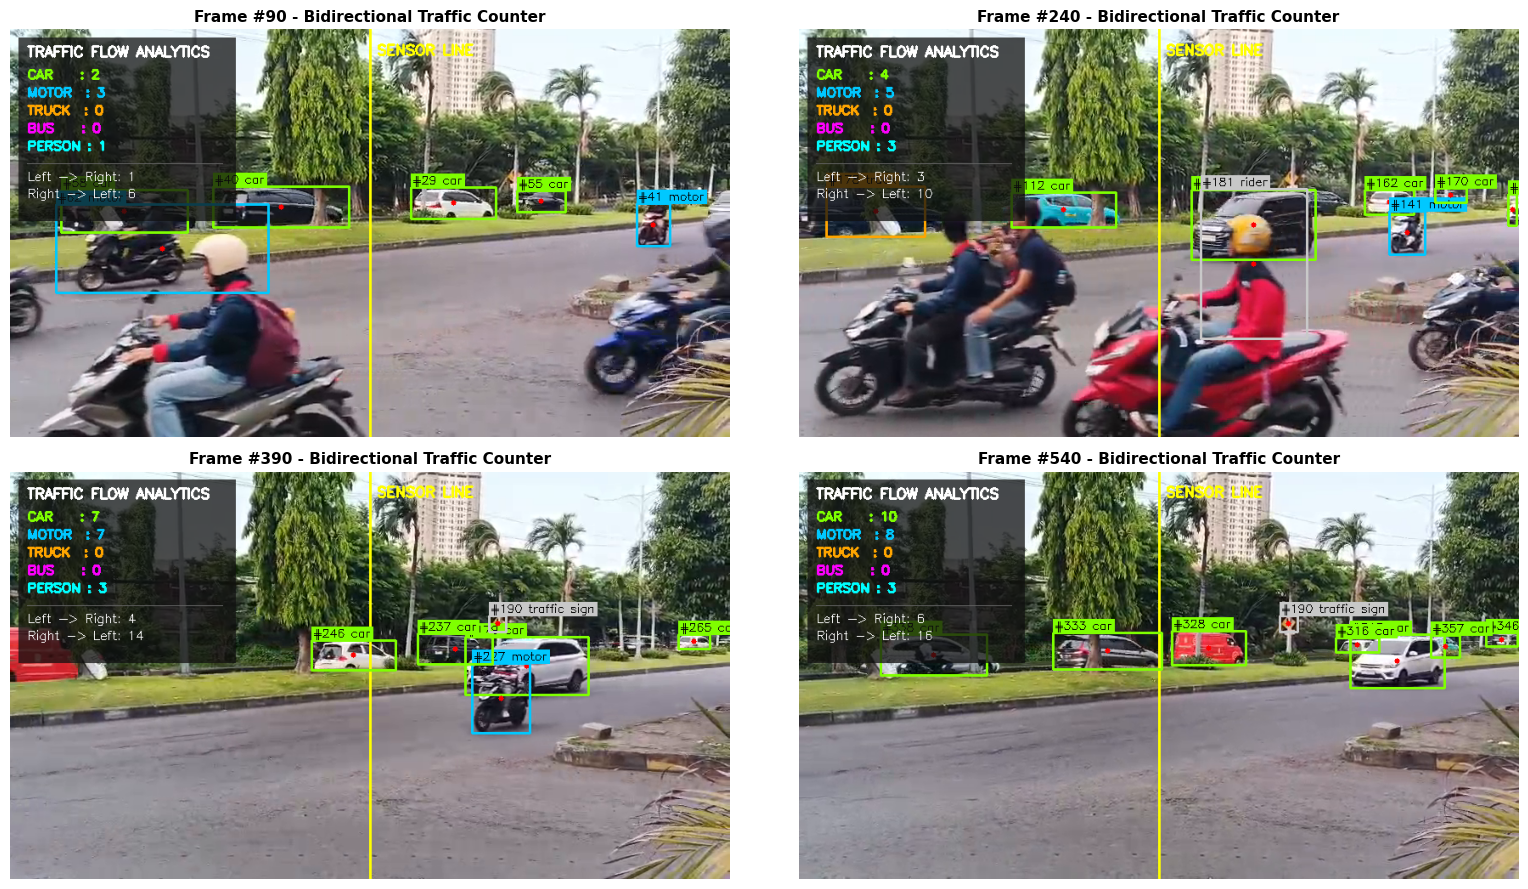

Selesai! Hasil Hitungan Akhir: {'car': 11, 'motor': 8, 'truck': 0, 'bus': 0, 'person': 3}
Arus Arah Lalu Lintas: {'Left -> Right': 7, 'Right -> Left': 16}


In [8]:
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO

model = YOLO('/kaggle/input/models/wannnsion95/bdd-weights/pytorch/default/1/best.pt')
video_input = "/kaggle/input/datasets/wannnsion95/video1/dataset1.mp4"
video_output = "/kaggle/working/traffic_analytics_v2.mp4"

cap = cv2.VideoCapture(video_input)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = int(cap.get(cv2.CAP_PROP_FPS)) or 30
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter(video_output, fourcc, fps, (width, height))

counting_line_x = int(width * 0.50)

counted_ids = set()
class_counts = {"car": 0, "motor": 0, "truck": 0, "bus": 0, "person": 0}
direction_counts = {"Left -> Right": 0, "Right -> Left": 0}
track_history_x = {}

COLORS = {
    "car": (0, 255, 127),
    "motor": (255, 200, 0),
    "truck": (0, 165, 255),
    "bus": (255, 0, 255),
    "person": (255, 255, 0),
}

max_frames = min(total_frames, 600)
frame_idx = 0
gif_frames = []
preview_frames = []
sample_indices = [int(max_frames * r) for r in [0.15, 0.40, 0.65, 0.90]]

while cap.isOpened() and frame_idx < max_frames:
    ret, frame = cap.read()
    if not ret:
        break
    frame_idx += 1

    results = model.track(frame, persist=True, tracker="bytetrack.yaml", conf=0.35, verbose=False)
    res = results[0]

    cv2.line(frame, (counting_line_x, 0), (counting_line_x, height), (0, 255, 255), 2)
    cv2.putText(frame, "SENSOR LINE", (counting_line_x + 8, 30),
                cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 255, 255), 2)

    if res.boxes is not None and res.boxes.id is not None:
        boxes = res.boxes.xyxy.cpu().numpy()
        track_ids = res.boxes.id.int().cpu().numpy()
        cls_ids = res.boxes.cls.int().cpu().numpy()

        for box, track_id, cls_id in zip(boxes, track_ids, cls_ids):
            x1, y1, x2, y2 = map(int, box)
            cls_name = model.names[cls_id]
            cx, cy = (x1 + x2) // 2, (y1 + y2) // 2

            color = COLORS.get(cls_name, (200, 200, 200))

            cv2.rectangle(frame, (x1, y1), (x2, y2), color, 2)
            cv2.circle(frame, (cx, cy), 3, (0, 0, 255), -1)

            label = f"#{track_id} {cls_name}"
            (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.45, 1)
            cv2.rectangle(frame, (x1, y1 - th - 6), (x1 + tw + 4, y1), color, -1)
            cv2.putText(frame, label, (x1 + 2, y1 - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 0), 1)

            prev_x = track_history_x.get(track_id, cx)
            if track_id not in counted_ids:
                if prev_x < counting_line_x <= cx:
                    counted_ids.add(track_id)
                    direction_counts["Left -> Right"] += 1
                    if cls_name in class_counts:
                        class_counts[cls_name] += 1
                elif prev_x > counting_line_x >= cx:
                    counted_ids.add(track_id)
                    direction_counts["Right -> Left"] += 1
                    if cls_name in class_counts:
                        class_counts[cls_name] += 1
            track_history_x[track_id] = cx

    overlay = frame.copy()
    cv2.rectangle(overlay, (10, 10), (265, 225), (15, 15, 15), -1)
    frame = cv2.addWeighted(overlay, 0.75, frame, 0.25, 0)

    cv2.putText(frame, "TRAFFIC FLOW ANALYTICS", (20, 32), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 2)
    y_pos = 58
    for k, v in class_counts.items():
        c = COLORS.get(k, (255, 255, 255))
        cv2.putText(frame, f"{k.upper():<7}: {v}", (20, y_pos), cv2.FONT_HERSHEY_SIMPLEX, 0.5, c, 2)
        y_pos += 21

    cv2.line(frame, (20, y_pos - 5), (250, y_pos - 5), (100, 100, 100), 1)
    y_pos += 15
    for d_label, d_val in direction_counts.items():
        cv2.putText(frame, f"{d_label}: {d_val}", (20, y_pos), cv2.FONT_HERSHEY_SIMPLEX, 0.48, (255, 255, 255), 1)
        y_pos += 20

    out.write(frame)

    rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    if frame_idx in sample_indices and len(preview_frames) < 4:
        preview_frames.append((frame_idx, rgb_frame))
    if frame_idx % 5 == 0:
        gif_frames.append(Image.fromarray(rgb_frame).resize((640, 362)))

cap.release()
out.release()

gif_path = "/kaggle/working/traffic_analytics_demo.gif"
gif_frames[0].save(gif_path, save_all=True, append_images=gif_frames[1:], duration=75, loop=0, optimize=True)

fig, axes = plt.subplots(2, 2, figsize=(16, 9))
axes = axes.flatten()
for i, (f_idx, img) in enumerate(preview_frames):
    axes[i].imshow(img)
    axes[i].set_title(f"Frame #{f_idx} - Bidirectional Traffic Counter", fontsize=11, fontweight='bold')
    axes[i].axis('off')

plt.tight_layout()
plt.savefig("/kaggle/working/traffic_analytics_frames.png", dpi=150)
plt.show()

print("Selesai! Hasil Hitungan Akhir:", class_counts)
print("Arus Arah Lalu Lintas:", direction_counts)